# Modelo de Volatilidad
**Proyecto Integrador · Aprendizaje Profundo**
Estación A001 — Brasília, DF · 2020–2026

---

## 1. Introducción

El enunciado pide un modelo orientado tanto al **nivel** de la serie como a su **volatilidad o variabilidad**. Los cuadernos 2 y 3 modelan el nivel (velocidad del viento). Este cuaderno modela la volatilidad con el mismo protocolo de validación.

La volatilidad es la **volatilidad histórica realizada** calculada en el EDA (cuaderno 1): la desviación estándar móvil de 28 días de los retornos logarítmicos,

$$\sigma_t = \sqrt{\frac{1}{n-1}\sum_{i=0}^{n-1}\left(r_{t-i}-\bar r_t\right)^2}, \qquad r_t = \ln\frac{v_t}{v_{t-1}}, \qquad n = 28,$$

donde $v_t$ es la velocidad media diaria del viento. El MLP recibe los últimos `lag` valores de $\sigma_t$ y predice $\sigma_{t+1}, …, \sigma_{t+H}$, solo a partir de observaciones históricas.

Decisiones de diseño:

- **Mismo protocolo que el cuaderno 3:** Forward Chaining de `timeseries-cv` agrupado en 5 folds con purga, escaladores ajustados solo con el entrenamiento y el mismo hold-out temporal (último 10 %). Se usa solo Forward Chaining porque fue la estrategia elegida en el cuaderno 3 por respetar la causalidad.
- **Arquitecturas reutilizadas:** para cada combinación lag × horizonte se usa la arquitectura elegida en el cuaderno 2 para el nivel, que tiene la misma dimensión de entrada y de salida. No se repite la búsqueda, que costaría otros 734 entrenamientos.
- **Referencia de persistencia:** una desviación estándar móvil de 28 días cambia muy despacio, de modo que predecir $\hat\sigma_{t+h} = \sigma_t$ ya es una referencia exigente. El MLP solo aporta valor si mejora a la persistencia.

---

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import gc
import ast
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.stattools import bds

from tsxv.splitTrainVal import split_train_val_forwardChaining

tf.get_logger().setLevel('ERROR')
tf.keras.utils.set_random_seed(42)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.prop_cycle': matplotlib.cycler('color', ['#000000', '#444444', '#888888', '#bbbbbb']),
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.size': 10, 'axes.titlesize': 11,
})

BASE_DIR    = os.path.dirname(os.getcwd())
DATA_PATH   = os.path.join(BASE_DIR, 'data', 'dataset.csv')
RESULTS_DIR = os.path.join(BASE_DIR, 'results')
APP_DIR     = os.path.join(BASE_DIR, 'app')
FIGS_DIR    = os.path.join(os.getcwd(), 'figs')
LOG_PATH    = os.path.join(RESULTS_DIR, 'progreso_volatilidad.log')
os.makedirs(FIGS_DIR, exist_ok=True)
print(f'TensorFlow: {tf.__version__}')

TensorFlow: 2.21.0


## 2. Datos, parámetros y arquitecturas

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['date'])
df = df.sort_values('date').reset_index(drop=True)
df = df[df.date >= '2020-01-01'].reset_index(drop=True)

y_full = df['volatility'].values.astype(np.float32)
fechas = df['date'].values

LAGS_LIST     = [7, 14, 21, 28]
HORIZONS_LIST = [7, 14, 21, 28]
N_STEPS_JUMP  = 7
HOLDOUT_FRAC  = 0.10
K_FOLDS       = 5
EPOCHS_FINAL  = 100
BATCH_SIZE    = 32
DROPOUT_RATE  = 0.5

n_hold        = max(int(len(y_full) * HOLDOUT_FRAC), 2 * max(HORIZONS_LIST))
serie_cv      = y_full[:-n_hold]
serie_holdout = y_full[-n_hold:]
fechas_cv     = fechas[:len(serie_cv)]
fechas_ho     = fechas[len(serie_cv):]

arch_df = pd.read_csv(os.path.join(RESULTS_DIR, 'best_architecture_summary.csv'))


def get_best_arch(lag, H):
    row = arch_df[(arch_df.lag == lag) & (arch_df.horizonte == H)].iloc[0]
    return ast.literal_eval(row['arquitectura']), ast.literal_eval(row['dropout_mask'])


print(f'Volatilidad 2020-2026: media={y_full.mean():.4f}, desv.={y_full.std():.4f}, min={y_full.min():.4f}, max={y_full.max():.4f}')
print(f'Serie CV: {len(serie_cv)} | Hold-out: {len(serie_holdout)} (desde {pd.Timestamp(fechas_ho[0]).date()})')

Volatilidad 2020-2026: media=0.2420, desv.=0.0347, min=0.1537, max=0.3460
Serie CV: 2247 | Hold-out: 249 (desde 2026-02-25)


## 3. Funciones auxiliares

Las funciones de partición, modelo y métricas son las del cuaderno 3. `persistencia` construye la referencia $\hat\sigma_{t+h} = \sigma_t$ para todos los pasos del horizonte.

In [3]:
def registrar(msg):
    linea = f'[{time.strftime("%H:%M:%S")}] {msg}'
    print(linea, flush=True)
    with open(LOG_PATH, 'a', encoding='utf-8') as f:
        f.write(linea + '\n')


def particiones_fc(n_obs, lag, H, jump=N_STEPS_JUMP, k=K_FOLDS):
    """Forward Chaining de tsxv agrupado en k folds con purga (índices temporales)."""
    X, y, Xcv, ycv = split_train_val_forwardChaining(np.arange(n_obs), numInputs=lag, numOutputs=H, numJumps=jump)
    folds = sorted(X)
    bordes = np.linspace(0, len(folds), k + 2).astype(int)
    salida = []
    for b in range(1, k + 1):
        folds_val = folds[bordes[b]:bordes[b + 1]]
        Xv = np.vstack([Xcv[f] for f in folds_val])
        yv = np.vstack([ycv[f] for f in folds_val])
        Xt, yt = X[folds_val[0]], y[folds_val[0]]
        sin_solape = yt.max(axis=1) < Xv.min()
        salida.append((Xt[sin_solape], yt[sin_solape], Xv, yv))
    return salida


def ventanas_holdout(lag, H):
    base = np.concatenate([serie_cv[-lag:], serie_holdout])
    n = len(base) - lag - H + 1
    X = np.array([base[i:i + lag] for i in range(n)], dtype=np.float32)
    y = np.array([base[i + lag:i + lag + H] for i in range(n)], dtype=np.float32)
    return X, y


def construir_modelo(arquitectura, dropout_mask, input_dim, n_outputs, dropout_rate=DROPOUT_RATE):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(input_dim,)))
    for idx, units in enumerate(arquitectura):
        model.add(tf.keras.layers.Dense(units, activation='relu'))
        if dropout_mask[idx]:
            model.add(tf.keras.layers.Dropout(dropout_rate))
    model.add(tf.keras.layers.Dense(n_outputs))
    model.compile(optimizer='adam', loss='mse', metrics=[tf.keras.metrics.RootMeanSquaredError()])
    return model


def callbacks_entrenamiento():
    return [
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, min_delta=1e-4,
                                         restore_best_weights=True, start_from_epoch=5),
    ]


def metricas(y_real, y_pred):
    rmse_h = np.sqrt(np.mean((y_real - y_pred) ** 2, axis=0))
    return {
        'rmse': float(rmse_h.mean()),
        'mae': float(np.mean(np.abs(y_real - y_pred))),
        'mse': float(np.mean((y_real - y_pred) ** 2)),
        'mape': float(np.mean(np.abs((y_real - y_pred) / np.abs(y_real))) * 100),
        'rmse_h': rmse_h,
    }


def persistencia(X, H):
    return np.repeat(X[:, -1:], H, axis=1)


def bds_pvalue(resid):
    try:
        _, pval = bds(np.asarray(resid, dtype=float), max_dim=2)
        return float(np.atleast_1d(pval)[0])
    except Exception:
        return float('nan')


print('Funciones auxiliares definidas.')

Funciones auxiliares definidas.


## 4. Validación cruzada (Forward Chaining, 5 folds)

Para cada combinación lag × horizonte y cada fold se entrena el MLP y se compara con la persistencia en el mismo conjunto de validación. El avance queda en `results/progreso_volatilidad.log`.

In [4]:
fold_rows, h_rows = [], []
if os.path.exists(LOG_PATH):
    os.remove(LOG_PATH)
registrar('Inicio: modelo de volatilidad, 16 combinaciones × 5 folds (Forward Chaining)')
t0 = time.time()
configs = [(lag, H) for lag in LAGS_LIST for H in HORIZONS_LIST]

for n_cfg, (lag, H) in enumerate(configs, 1):
    arch, dmask = get_best_arch(lag, H)
    for fold, (it, iyt, iv, iyv) in enumerate(particiones_fc(len(serie_cv), lag, H), 1):
        Xt, yt, Xv, yv = serie_cv[it], serie_cv[iyt], serie_cv[iv], serie_cv[iyv]
        sx, sy = StandardScaler().fit(Xt), StandardScaler().fit(yt)
        tf.keras.backend.clear_session()
        model = construir_modelo(arch, dmask, lag, H)
        hist = model.fit(sx.transform(Xt), sy.transform(yt),
                         validation_data=(sx.transform(Xv), sy.transform(yv)),
                         epochs=EPOCHS_FINAL, batch_size=BATCH_SIZE, shuffle=False, verbose=0,
                         callbacks=callbacks_entrenamiento())
        yhat = sy.inverse_transform(model(sx.transform(Xv), training=False).numpy())
        m, mp = metricas(yv, yhat), metricas(yv, persistencia(Xv, H))
        fold_rows.append({
            'lag': lag, 'horizonte': H, 'fold': fold, 'n_train': len(Xt), 'n_val': len(Xv),
            'rmse': m['rmse'], 'mae': m['mae'], 'mse': m['mse'], 'mape': m['mape'],
            'rmse_persistencia': mp['rmse'], 'mape_persistencia': mp['mape'],
            'bds_pvalue_h1': bds_pvalue(yv[:, 0] - yhat[:, 0]),
            'mejor_epoca': int(np.argmin(hist.history['val_loss']) + 1),
        })
        for h in range(H):
            h_rows.append({'lag': lag, 'horizonte': H, 'fold': fold, 'h': h + 1,
                           'rmse': m['rmse_h'][h], 'rmse_persistencia': mp['rmse_h'][h]})
        del model
    gc.collect()
    transcurrido = time.time() - t0
    registrar(f'lag={lag} H={H} ({n_cfg}/{len(configs)}) | {transcurrido / 60:.1f} min | '
              f'faltan ~{transcurrido / n_cfg * (len(configs) - n_cfg) / 60:.1f} min')

vol_folds = pd.DataFrame(fold_rows)
vol_h = pd.DataFrame(h_rows)
vol_folds.to_csv(os.path.join(RESULTS_DIR, 'vol_cv_metricas_por_fold.csv'), index=False)
vol_h.to_csv(os.path.join(RESULTS_DIR, 'vol_cv_metricas_por_h.csv'), index=False)
registrar('Validación cruzada de volatilidad terminada')

[19:32:18] Inicio: modelo de volatilidad, 16 combinaciones × 5 folds (Forward Chaining)


[19:33:12] lag=7 H=7 (1/16) | 0.9 min | faltan ~13.4 min


[19:33:43] lag=7 H=14 (2/16) | 1.4 min | faltan ~9.9 min


[19:34:29] lag=7 H=21 (3/16) | 2.2 min | faltan ~9.5 min


[19:35:24] lag=7 H=28 (4/16) | 3.1 min | faltan ~9.3 min


[19:35:59] lag=14 H=7 (5/16) | 3.7 min | faltan ~8.1 min


... (8 outputs left out)

[19:42:51] lag=28 H=14 (14/16) | 10.6 min | faltan ~1.5 min


[19:43:37] lag=28 H=21 (15/16) | 11.3 min | faltan ~0.8 min


[19:44:30] lag=28 H=28 (16/16) | 12.2 min | faltan ~0.0 min


[19:44:30] Validación cruzada de volatilidad terminada


## 5. MLP frente a persistencia en validación

`mejora_%` es la reducción relativa del RMSE del MLP respecto de la persistencia: un valor positivo indica que el MLP predice mejor que repetir la última volatilidad observada.

,lag,horizonte,rmse,rmse_persistencia,mape,mape_persistencia,mae,mse,bds_pvalue_h1,mejora_%
0,7,7,0.0175,0.0180,6.0616,5.8396,0.0139,0.0003,0.1725,2.9765
1,7,14,0.0229,0.0253,8.0711,8.3379,0.0184,0.0006,0.3066,9.2239
2,7,21,0.0266,0.0303,9.5826,10.1249,0.0217,0.0008,0.1652,12.1112
3,7,28,0.0286,0.0345,10.3647,11.5843,0.0234,0.0009,0.2472,17.1661
4,14,7,0.0180,0.0181,6.3364,5.8504,0.0144,0.0003,0.1172,0.3575
5,14,14,0.0234,0.0253,8.2311,8.3153,0.0188,0.0006,0.1979,7.6888
6,14,21,0.0264,0.0303,9.4476,10.0826,0.0214,0.0007,0.4066,12.9104
7,14,28,0.0287,0.0345,10.3433,11.5469,0.0234,0.0009,0.1898,16.8135
8,21,7,0.0186,0.0181,6.4649,5.8445,0.0148,0.0004,0.3899,-2.6895
9,21,14,0.0235,0.0254,8.3002,8.3133,0.0189,0.0006,0.2733,7.1867


=== RMSE val MLP — lag × horizonte ===


horizonte,7,14,21,28
lag,,,,
7,0.0175,0.0229,0.0266,0.0286
14,0.0180,0.0234,0.0264,0.0287
21,0.0186,0.0235,0.0269,0.0288
28,0.0196,0.0236,0.0276,0.0297


=== Mejora del MLP sobre la persistencia (%) — lag × horizonte ===


horizonte,7,14,21,28
lag,,,,
7,3.0,9.2,12.1,17.2
14,0.4,7.7,12.9,16.8
21,-2.7,7.2,11.4,16.9
28,-7.7,7.2,9.5,14.4


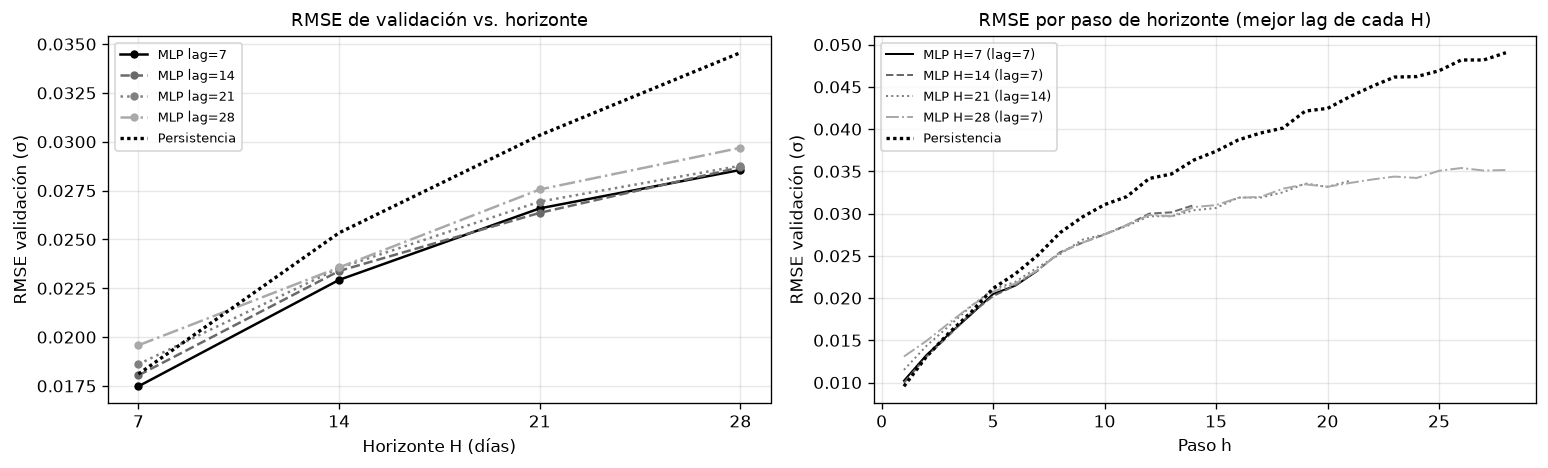

In [5]:
vol_comp = (vol_folds.groupby(['lag', 'horizonte'])
            [['rmse', 'rmse_persistencia', 'mape', 'mape_persistencia', 'mae', 'mse', 'bds_pvalue_h1']]
            .mean().reset_index())
vol_comp['mejora_%'] = (1 - vol_comp['rmse'] / vol_comp['rmse_persistencia']) * 100
vol_comp.to_csv(os.path.join(RESULTS_DIR, 'vol_cv_comparativa.csv'), index=False)
display(vol_comp.round(4))

print('=== RMSE val MLP — lag × horizonte ===')
display(vol_comp.pivot(index='lag', columns='horizonte', values='rmse').round(4))
print('=== Mejora del MLP sobre la persistencia (%) — lag × horizonte ===')
display(vol_comp.pivot(index='lag', columns='horizonte', values='mejora_%').round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, lag in enumerate(LAGS_LIST):
    sub = vol_comp[vol_comp.lag == lag].sort_values('horizonte')
    axes[0].plot(sub.horizonte, sub.rmse, ls=['-', '--', ':', '-.'][i], marker='o', ms=4,
                 color=['black', 'dimgray', 'gray', 'darkgray'][i], label=f'MLP lag={lag}')
per = vol_comp.groupby('horizonte')['rmse_persistencia'].mean()
axes[0].plot(per.index, per.values, color='black', lw=2, ls=(0, (1, 1)), label='Persistencia')
axes[0].set_xlabel('Horizonte H (días)')
axes[0].set_ylabel('RMSE validación (σ)')
axes[0].set_xticks(HORIZONS_LIST)
axes[0].set_title('RMSE de validación vs. horizonte')
axes[0].legend(fontsize=8)

for i, H in enumerate(HORIZONS_LIST):
    lag_b = int(vol_comp[vol_comp.horizonte == H].sort_values('rmse').iloc[0]['lag'])
    sub = vol_h[(vol_h.lag == lag_b) & (vol_h.horizonte == H)].groupby('h')[['rmse', 'rmse_persistencia']].mean()
    axes[1].plot(sub.index, sub.rmse, ls=['-', '--', ':', '-.'][i], color=['black', 'dimgray', 'gray', 'darkgray'][i],
                 lw=1.2, label=f'MLP H={H} (lag={lag_b})')
axes[1].plot(sub.index, sub.rmse_persistencia, color='black', lw=2, ls=(0, (1, 1)), label='Persistencia')
axes[1].set_xlabel('Paso h')
axes[1].set_ylabel('RMSE validación (σ)')
axes[1].set_title('RMSE por paso de horizonte (mejor lag de cada H)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'vol_rmse_vs_horizonte.png'), dpi=150)
plt.show()

**Interpretación.** En validación el MLP mejora a la persistencia en 14 de las 16 combinaciones, y la ventaja crece con el horizonte: con H = 7 va de −7,7 % a 3,0 % según el lag, con H = 14 de 7,2 % a 9,2 %, con H = 21 de 9,5 % a 12,9 % y con H = 28 de 14,4 % a 17,2 %. El lag de 7 días es el mejor, o casi, en todos los horizontes: con él, el RMSE del MLP pasa de 0,0175 con H = 7 a 0,0286 con H = 28, frente a 0,0181 y 0,0346 de la persistencia. El MAPE medio es de 8,7 % (9,0 % para la persistencia), el MLP gana en el 78,8 % de los folds y solo en el primer paso del horizonte la persistencia sigue siendo ligeramente mejor (RMSE de 0,0095 frente a 0,0100–0,0131).

Esto significa que la volatilidad, a diferencia del nivel, sí es predecible a partir de su propio pasado. Como es una desviación estándar móvil de 28 días, cambia lentamente y la persistencia es casi imbatible a un día, pero a varias semanas tiende a volver a su nivel medio, y el MLP aprende esa reversión a la media que la persistencia ignora (Engle & Patton, 2001). Hay que tener en cuenta que una parte de esa predictibilidad es mecánica: la volatilidad de mañana comparte 27 de sus 28 retornos con la de hoy, por el solapamiento de las ventanas móviles.

Por tal motivo, se opta por elegir en cada horizonte el lag de menor RMSE de validación para el modelo final, y por presentar la mejora frente a la persistencia, y no solo el error absoluto, como la medida del aporte del modelo (Hyndman & Athanasopoulos, 2021).

## 6. Modelo final de volatilidad y evaluación en el hold-out

Igual que en el cuaderno 3: para cada horizonte se elige el lag con menor RMSE de validación, se reentrena con toda la serie previa al hold-out durante la mediana de la mejor época de sus folds y se evalúa una sola vez en el hold-out, junto con la persistencia. Los modelos se guardan en `app/model_vol_h{H}.keras`.

In [6]:
ho_rows, ho_frames = [], []
for H in HORIZONS_LIST:
    lag = int(vol_comp[vol_comp.horizonte == H].sort_values('rmse').iloc[0]['lag'])
    arch, dmask = get_best_arch(lag, H)
    epocas = max(int(vol_folds[(vol_folds.lag == lag) & (vol_folds.horizonte == H)]['mejor_epoca'].median()), 10)
    X, y, Xcv, ycv = split_train_val_forwardChaining(np.arange(len(serie_cv)), numInputs=lag,
                                                    numOutputs=H, numJumps=N_STEPS_JUMP)
    u = max(X)
    Xt, yt = serie_cv[np.vstack([X[u], Xcv[u]])], serie_cv[np.vstack([y[u], ycv[u]])]
    sx, sy = StandardScaler().fit(Xt), StandardScaler().fit(yt)
    tf.keras.backend.clear_session()
    model = construir_modelo(arch, dmask, lag, H)
    model.fit(sx.transform(Xt), sy.transform(yt), epochs=epocas, batch_size=BATCH_SIZE, shuffle=False, verbose=0)

    X_ho, y_ho = ventanas_holdout(lag, H)
    yhat = sy.inverse_transform(model(sx.transform(X_ho), training=False).numpy())
    m, mp = metricas(y_ho, yhat), metricas(y_ho, persistencia(X_ho, H))
    ho_rows.append({'horizonte': H, 'lag': lag, 'arquitectura': str(arch), 'dropout_mask': str(dmask),
                    'epocas': epocas, 'n_holdout': len(X_ho),
                    'holdout_rmse': m['rmse'], 'holdout_mape': m['mape'], 'holdout_mae': m['mae'],
                    'rmse_persistencia': mp['rmse'], 'mejora_%': (1 - m['rmse'] / mp['rmse']) * 100,
                    'bds_pvalue_h1': bds_pvalue(y_ho[:, 0] - yhat[:, 0])})
    ho_frames.append(pd.DataFrame({'horizonte': H, 'lag': lag, 'fecha': fechas_ho[:len(X_ho)],
                                   'real': y_ho[:, 0], 'pred': yhat[:, 0], 'persistencia': X_ho[:, -1]}))
    model.save(os.path.join(APP_DIR, f'model_vol_h{H}.keras'))
    joblib.dump({'x': sx, 'y': sy, 'lag': lag}, os.path.join(APP_DIR, f'scalers_vol_h{H}.joblib'))
    registrar(f'Volatilidad H={H} (lag={lag}): RMSE hold-out={m["rmse"]:.4f} | persistencia={mp["rmse"]:.4f}')

vol_ho = pd.DataFrame(ho_rows)
vol_ho_pred = pd.concat(ho_frames, ignore_index=True)
vol_ho.to_csv(os.path.join(RESULTS_DIR, 'vol_holdout_evaluation.csv'), index=False)
vol_ho_pred.to_csv(os.path.join(RESULTS_DIR, 'vol_holdout_predicciones.csv'), index=False)
registrar('Fin del cuaderno 5: modelos de volatilidad guardados')
display(vol_ho.round(4))

[19:44:37] Volatilidad H=7 (lag=7): RMSE hold-out=0.0177 | persistencia=0.0178


[19:44:41] Volatilidad H=14 (lag=7): RMSE hold-out=0.0219 | persistencia=0.0232


[19:44:44] Volatilidad H=21 (lag=14): RMSE hold-out=0.0240 | persistencia=0.0275


[19:44:52] Volatilidad H=28 (lag=7): RMSE hold-out=0.0260 | persistencia=0.0313


[19:44:52] Fin del cuaderno 5: modelos de volatilidad guardados


,horizonte,lag,arquitectura,dropout_mask,epocas,n_holdout,holdout_rmse,holdout_mape,holdout_mae,rmse_persistencia,mejora_%,bds_pvalue_h1
0,7,7,"(64, 256, 128)","(False, True, True)",27,243,0.0177,5.2103,0.0129,0.0178,0.1908,0.4069
1,14,7,"(64, 128, 256)","(False, False, True)",17,236,0.0219,6.4051,0.0160,0.0232,5.7645,0.5457
2,21,14,"(64, 128, 256)","(False, False, True)",21,229,0.0240,7.1963,0.0181,0.0275,12.5462,0.0000
3,28,7,"(256, 32, 128)","(False, True, True)",70,222,0.0260,7.9392,0.0201,0.0313,16.9169,0.8357


**Interpretación.** En el hold-out los modelos finales, con lag de 7 días en H = 7, 14 y 28 y de 14 días en H = 21, obtienen un RMSE de 0,0177 a 0,0260 y un MAPE de 5,2 % a 7,9 %. Frente a la persistencia, la mejora es prácticamente nula con H = 7 (0,2 %) y crece a 5,8 % con H = 14, 12,5 % con H = 21 y 16,9 % con H = 28, el mismo patrón de la validación. La prueba BDS no rechaza la independencia de los residuos del primer paso con H = 7, 14 y 28 (p-valores de 0,41, 0,55 y 0,84), pero sí con H = 21 (p-valor inferior a 0,0001).

Lo anterior indica que el modelo de volatilidad generaliza: la ventaja sobre la persistencia observada en validación se reproduce en datos que nunca intervinieron en el entrenamiento ni en la selección. El rechazo de la BDS con H = 21, el único modelo con lag de 14 días, señala que en ese horizonte queda estructura sin capturar, aunque su error es coherente con el de los demás horizontes.

En consecuencia, se decide guardar los cuatro modelos de volatilidad en `app/` (`model_vol_h{H}.keras`) como complemento del modelo de nivel, con la recomendación de usarlos sobre todo en horizontes de 14 a 28 días, donde aportan frente a la persistencia.

### 6.1 Volatilidad real y predicha en el hold-out

Primer paso del horizonte ($h = 1$) para el modelo final de cada H, junto con la persistencia.

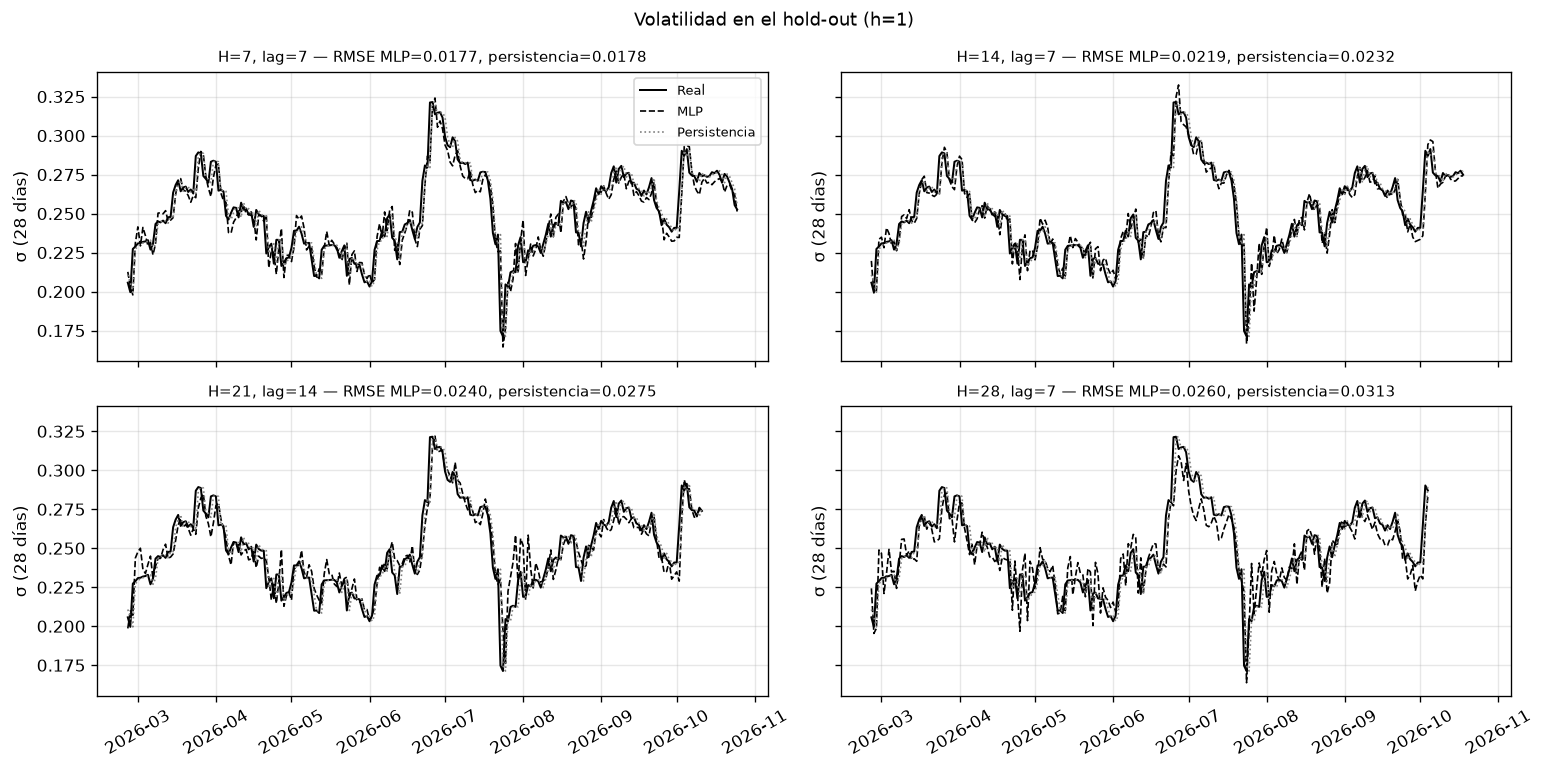

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True, sharey=True)
for ax, H in zip(axes.ravel(), HORIZONS_LIST):
    p = vol_ho_pred[vol_ho_pred.horizonte == H]
    fila = vol_ho[vol_ho.horizonte == H].iloc[0]
    ax.plot(p.fecha, p.real, color='black', lw=1.2, label='Real')
    ax.plot(p.fecha, p.pred, color='black', lw=1.0, ls='--', label='MLP')
    ax.plot(p.fecha, p.persistencia, color='gray', lw=1.0, ls=':', label='Persistencia')
    ax.set_title(f'H={H}, lag={int(fila.lag)} — RMSE MLP={fila.holdout_rmse:.4f}, persistencia={fila.rmse_persistencia:.4f}',
                 fontsize=9)
    ax.set_ylabel('σ (28 días)')
    ax.tick_params(axis='x', labelrotation=30)
axes[0, 0].legend(fontsize=8)
plt.suptitle('Volatilidad en el hold-out (h=1)', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, 'vol_holdout_real_vs_pred.png'), dpi=150)
plt.show()

**Interpretación.** En el hold-out la volatilidad real va de 0,171 a 0,322, y el MLP la sigue de cerca en los cuatro horizontes: la correlación entre lo predicho y lo real en el primer paso va de 0,86 (H = 28) a 0,92 (H = 14), y la desviación estándar de lo predicho es entre el 83 % y el 97 % de la real. A diferencia del modelo de nivel, aquí las predicciones no se aplanan hacia la media, y la persistencia, por construcción, reproduce la serie con un día de retraso.

Así mismo, como la figura muestra solo el primer paso, donde la persistencia es muy competitiva, la ventaja del MLP no se aprecia aquí sino en los pasos lejanos del horizonte (sección 5): su valor está en anticipar hacia dónde se moverá la volatilidad en las semanas siguientes, no en el dato de mañana.

Por ello, se recomienda acompañar esta figura con el RMSE por paso de horizonte al presentar los resultados, y usar el modelo de volatilidad como insumo para la gestión de la incertidumbre del pronóstico de nivel, por ejemplo para ampliar o estrechar los intervalos según la volatilidad esperada.

---

## 7. Conclusiones

1. La volatilidad histórica, la desviación estándar móvil de 28 días de los retornos logarítmicos, se modeló con el mismo protocolo del nivel: Forward Chaining de `timeseries-cv` agrupado en cinco folds con purga, escaladores ajustados solo con el entrenamiento y hold-out del último 10 %.
2. A diferencia del nivel, la volatilidad es predecible y el MLP aporta: en el hold-out reduce el RMSE de la persistencia en 5,8 %, 12,5 % y 16,9 % con H = 14, 21 y 28, y empata con ella con H = 7.
3. La ventaja crece con el horizonte porque el MLP aprende la reversión de la volatilidad a su nivel medio. A un día, la persistencia sigue siendo casi imbatible por el solapamiento de las ventanas móviles.
4. Las arquitecturas se reutilizaron del cuaderno 2, sin una búsqueda específica para la volatilidad; una búsqueda propia podría mejorar el resultado y queda como trabajo futuro.
5. Con este cuaderno el proyecto cubre los dos objetivos del enunciado: la predicción del nivel de la serie (cuadernos 2 a 4) y la modelación de su variabilidad.

## Referencias

- Engle, R. F., & Patton, A. J. (2001). What good is a volatility model? *Quantitative Finance*, 1(2), 237–245.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3.ª ed.). OTexts.